There are 10 patients in the database. We generate 1000 thetas from the proposal distribution, which is equal to the prior distribution in our research for convenience's sake. Each weight is the product of the 10 patients' likelihoods at one theta. Laplace noise is added to the weights based on a decided epsilon value (0.1 here). The noisy weights and thetas are released.

The adversary has all the patient data except the second patient's. They will use the released pairs and their knowledge of the other patients to guess the x2 value.

In [174]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize

rng = np.random.default_rng(42)

In [175]:
# 10 patients generated using true theta plus noise to mimic real world analysis
n = 10
x = 1 + rng.standard_normal(n) 
print(x)
print(x.mean())

[ 1.30471708 -0.03998411  1.7504512   1.94056472 -0.95103519 -0.30217951
  1.1278404   0.68375741  0.98319884  0.14695607]
0.6644286915941287


In [176]:
N = 1000
theta = rng.standard_normal(N)
print(theta)

[ 8.79397975e-01  7.77791935e-01  6.60306976e-02  1.12724121e+00
  4.67509342e-01 -8.59292463e-01  3.68750784e-01 -9.58882601e-01
  8.78450301e-01 -4.99259110e-02 -1.84862364e-01 -6.80929544e-01
  1.22254134e+00 -1.54529482e-01 -4.28327822e-01 -3.52133550e-01
  5.32309186e-01  3.65444064e-01  4.12732612e-01  4.30821003e-01
  2.14164760e+00 -4.06415016e-01 -5.12242729e-01 -8.13772728e-01
  6.15979423e-01  1.12897229e+00 -1.13947458e-01 -8.40156477e-01
 -8.24481216e-01  6.50592788e-01  7.43254171e-01  5.43154268e-01
 -6.65509707e-01  2.32161323e-01  1.16685809e-01  2.18688597e-01
  8.71428778e-01  2.23595549e-01  6.78913563e-01  6.75790695e-02
  2.89119399e-01  6.31288226e-01 -1.45715582e+00 -3.19671216e-01
 -4.70372654e-01 -6.38877848e-01 -2.75142251e-01  1.49494131e+00
 -8.65831116e-01  9.68278355e-01 -1.68286977e+00 -3.34885030e-01
  1.62753065e-01  5.86222331e-01  7.11226580e-01  7.93347235e-01
 -3.48725072e-01 -4.62351793e-01  8.57975881e-01 -1.91304325e-01
 -1.27568632e+00 -1.13328

In [177]:
def calc_weights(theta, x):
    pdf_table = stats.norm.pdf(x, theta[:, None])#turning theta into column
    return pdf_table.prod(axis = 1)

w = calc_weights(theta, x)
print(theta[0], w[0])

0.8793979748628286 1.6059464873637936e-06


In [178]:
epsilon = np.geomspace(0.01, 1e9, 15)
print(epsilon)
epsilon_dp = 0.1

[1.00000000e-02 6.10540230e-02 3.72759372e-01 2.27584593e+00
 1.38949549e+01 8.48342898e+01 5.17947468e+02 3.16227766e+03
 1.93069773e+04 1.17876863e+05 7.19685673e+05 4.39397056e+06
 2.68269580e+07 1.63789371e+08 1.00000000e+09]


In [179]:
delta_w = (2 * np.pi) ** (-n /2) # max likelihood is when x = theta. likelihood becomes 1/root(2 pi). delta_w is likelihood ** n

scales = N * delta_w / epsilon
b_dp = N * delta_w / epsilon_dp
print(delta_w, scales, b_dp)


0.00010211761384541831 [1.02117614e+01 1.67257797e+00 2.73950493e-01 4.48701789e-02
 7.34925836e-03 1.20373040e-03 1.97158245e-04 3.22924249e-05
 5.28915595e-06 8.66307525e-07 1.41891964e-07 2.32403955e-08
 3.80652976e-09 6.23469114e-10 1.02117614e-10] 1.021176138454183


In [180]:
def add_laplace_noise(w, b):
    return w + rng.laplace(0, b, len(w))

w_hat = add_laplace_noise(w, b_dp)
print(w_hat)

[-4.35054855e-01 -9.46936672e-01  8.29821377e-01  1.30453147e+00
 -7.21474204e-01  4.17680333e-01 -1.38061577e+00 -6.09930653e-01
 -1.30978229e+00 -5.79336274e-01  4.39077836e-01  1.75482724e+00
 -9.22895231e-01  8.97731913e-02  5.26389154e-01  2.41284750e+00
  2.53883046e-01 -6.87173969e-01  2.95078459e-01 -4.54170018e-01
  3.10633432e+00 -2.28696006e-01  4.73207128e-01 -3.13426287e+00
 -2.27710014e-01  1.41653093e+00  2.54318624e-01 -1.21430279e-01
  2.09826057e+00  1.25696208e+00 -4.48689541e-01  9.52966573e-02
 -2.09968441e-02  3.13579054e-01 -4.11670397e-01 -7.31774132e-01
  1.78188769e+00  1.92208382e+00  1.18499627e+00  3.19924449e+00
  6.87570456e-01  7.69568047e-01  7.60592290e-01 -4.03945437e-02
 -9.30537795e-02 -7.48549479e-01  3.49222991e-01 -5.58659143e-01
 -6.76418279e-01  1.92644959e-01 -2.02697229e-01 -8.43686866e-01
  1.02115305e+00  1.30408968e+00 -1.11556583e+00 -4.28767964e+00
 -4.05519451e-01  9.23063298e-01  1.15830567e+00 -1.31218339e+00
  8.12407392e-01 -1.49456

$$w(\theta_j, x) = \underbrace{\prod_{i \ne 2} N(x_i \mid \theta_j, 1)}_{\text{known}} \; N(x_2 \mid \theta_j, 1)$$
$$L(x_2 \mid \hat w, x_{(2)}) = \prod_{j=1}^N \text{Laplace}\big(\hat w_j - w(\theta_j, x) \mid 0, b\big) = \prod_{j=1}^N \frac{1}{2b}\exp\left(-\frac{|\hat w_j - w(\theta_j, x)|}{b}\right)$$
$$\log L = -N \log(2b) - \frac{1}{b}\sum_{j=1}^N |\hat w_j - w(\theta_j, x)|$$
$$\hat x_2 = \arg\max_{x_2} \log L = \arg\min_{x_2} \frac{1}{b}\sum_{j=1}^N |\hat w_j - w(\theta_j, x)|$$

In [181]:
def negative_log_likelihood(x2, w_hat, w_known, theta):
    w_guess = w_known * stats.norm.pdf(x2, theta) # computed weights if x2 were patients real value 
    # multiplying the w_known with the missing likelihood gives us our estimate of w_hat

    return np.abs(w_hat - w_guess).sum() 
# instead of considering how likely is the x2 guess directly , we ask how likely is the noise required to give the weight for a given theta
# dropping the division by b as we only want comparison 

In [ ]:
x_known = np.delete(x, 1) # the attacker knows all the values of x except the second one
w_known = stats.norm.pdf(x_known, theta[:, None]).prod(axis = 1)
def attack(w_known, theta, w_hat):
    #uses brute force to check every guess on fixed range then after finding the right it uses the default
    # fmin to find the bottom
    return optimize.brute(negative_log_likelihood, ranges = ((-5, 5), ), args = (w_hat, w_known, theta), Ns = 101)[0]

print("actual x2", x[1])
print("guess with no noise", attack(w_known, theta, w))
print("guess with DP noise", attack(w_known, theta, w_hat))

acutal x2 -0.03998410624049553
guess with no noise -0.04000000000000001
guess with DP noise 1.5750000000000006


In [183]:
def attack_iteration():
    x = 1 + rng.standard_normal(n)
    theta = rng.standard_normal(N)
    w = calc_weights(theta, x)
    w_known = calc_weights(theta, np.delete(x, 1))
    # computing a guess for x2 at each noise level
    x2_computed = np.array([attack(w_known, theta, add_laplace_noise(w, b)) for b in scales])
    return (x2_computed - x[1]) ** 2

n_attacks = 1000
squared_errors = np.array([attack_iteration() for i in range(n_attacks)])

mse_per_b = squared_errors.mean(axis = 0)
se_per_b = squared_errors.std(axis = 0) / np.sqrt(n_attacks)



In [184]:
import pandas as pd
print(pd.DataFrame({"epsilon": epsilon, "scale b": scales, "mse": mse_per_b, "se": se_per_b}))

         epsilon       scale b        mse        se
0   1.000000e-02  1.021176e+01  12.757181  0.557172
1   6.105402e-02  1.672578e+00  12.678721  0.602629
2   3.727594e-01  2.739505e-01  14.250799  0.667033
3   2.275846e+00  4.487018e-02  16.576010  0.733858
4   1.389495e+01  7.349258e-03  17.553001  0.830330
5   8.483429e+01  1.203730e-03  15.797260  0.789258
6   5.179475e+02  1.971582e-04  14.948491  0.830022
7   3.162278e+03  3.229242e-05  10.506742  0.724782
8   1.930698e+04  5.289156e-06   5.200238  0.538964
9   1.178769e+05  8.663075e-07   2.128482  0.333358
10  7.196857e+05  1.418920e-07   0.265945  0.065253
11  4.393971e+06  2.324040e-08   0.017232  0.005875
12  2.682696e+07  3.806530e-09   0.049308  0.022151
13  1.637894e+08  6.234691e-10   0.070618  0.063212
14  1.000000e+09  1.021176e-10   0.000166  0.000154


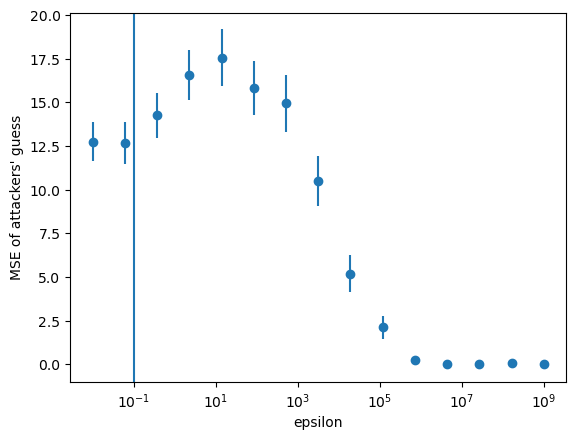

In [186]:
plt.errorbar(epsilon, mse_per_b, yerr = 1.96 * se_per_b, fmt = "o")
plt.axvline(epsilon_dp)
plt.xscale("log")
plt.xlabel("epsilon")
plt.ylabel("MSE of attackers' guess")
plt.show()
